Import required libraries

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix
)

In [5]:
df = pd.read_csv("diabetes.csv")
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [6]:
X = df.drop("Outcome",axis=1)
y = df["Outcome"]

In [7]:
X_train,X_test,y_train,y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Without feature scaling

In [11]:
model1 = LogisticRegression(max_iter=1000)
model1.fit(X_train,y_train)
pred1 = model1.predict(X_test)
print("WITHOUT FEATURE SCALING")
print("Accuracy :", accuracy_score(y_test, pred1))
print("Precision:", precision_score(y_test, pred1))
print("Recall   :", recall_score(y_test, pred1))
print("F1 Score :", f1_score(y_test, pred1))

WITHOUT FEATURE SCALING
Accuracy : 0.7467532467532467
Precision: 0.6379310344827587
Recall   : 0.6727272727272727
F1 Score : 0.6548672566371682


In [21]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, pred1))

Confusion Matrix:
[[78 21]
 [18 37]]


With feature scaling

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model2 = LogisticRegression(max_iter = 1000)
model2.fit(X_train_scaled,y_train)
pred2=model2.predict(X_test_scaled)
print("\nWITH FEATURE SCALING")
print("Accuracy :", accuracy_score(y_test, pred2))
print("Precision:", precision_score(y_test, pred2))
print("Recall   :", recall_score(y_test, pred2))
print("F1 Score :", f1_score(y_test, pred2))


WITH FEATURE SCALING
Accuracy : 0.7532467532467533
Precision: 0.6491228070175439
Recall   : 0.6727272727272727
F1 Score : 0.6607142857142857


In [20]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, pred2))

Confusion Matrix:
[[79 20]
 [18 37]]


Comparision

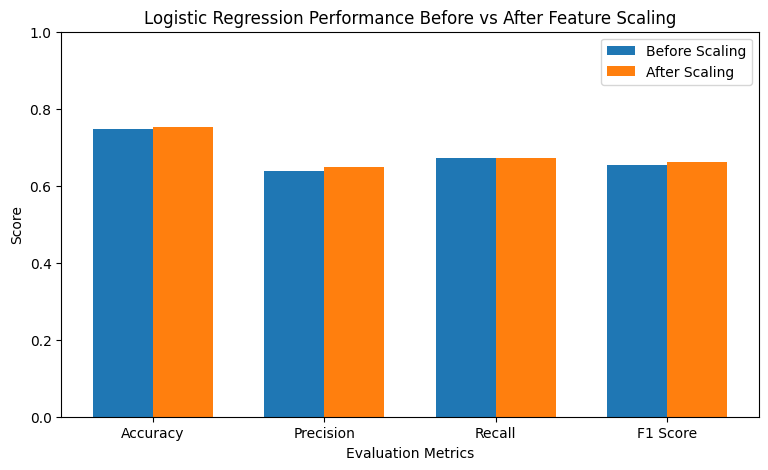

In [23]:

# Metrics before scaling
before = [
    accuracy_score(y_test, pred1),
    precision_score(y_test, pred1),
    recall_score(y_test, pred1),
    f1_score(y_test, pred1)
]

# Metrics after scaling
after = [
    accuracy_score(y_test, pred2),
    precision_score(y_test, pred2),
    recall_score(y_test, pred2),
    f1_score(y_test, pred2)
]

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, before, width, label='Before Scaling')
plt.bar(x + width/2, after, width, label='After Scaling')

plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.title('Logistic Regression Performance Before vs After Feature Scaling')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()

plt.show()